In [1]:
!pip install ultralytics
!pip install roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 6.9 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 69.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.9 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [2]:
from roboflow import Roboflow
import shutil
import os

In [3]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()

In [5]:
rf = Roboflow(api_key=user_secrets.get_secret("ROBOFLOW_API_KEY"))

In [6]:
project = rf.workspace("workspace-5ujvu").project("basketball-players-fy4c2-vfsuv")
version = project.version(17)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Basketball-Players-17 in yolov11:: 100%|██████████| 652/652 [00:00<00:00, 8831.40it/s]


In [7]:
os.listdir("/kaggle/working/Basketball-Players-17")

['train',
 'README.dataset.txt',
 'test',
 'README.roboflow.txt',
 'valid',
 'data.yaml']

In [8]:
from pathlib import Path
import pandas as pd
import yaml
from PIL import Image

root = Path("/kaggle/working/Basketball-Players-17")
names = yaml.safe_load(open(root / "data.yaml"))["names"]
if isinstance(names, list):
    names = dict(enumerate(names))

rows = []
for split in ["train", "valid", "test"]:
    img_dir = root / split / "images"
    lbl_dir = root / split / "labels"
    if not img_dir.exists():
        continue
    for img_path in img_dir.iterdir():
        if img_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
            continue
        w, h = Image.open(img_path).size
        lbl = lbl_dir / f"{img_path.stem}.txt"
        lines = lbl.read_text().strip().splitlines() if lbl.exists() else []
        if not lines:
            rows.append(dict(split=split, image=img_path.name, img_w=w, img_h=h, cls=None))
            continue
        for line in lines:
            parts = line.split()
            c, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:5])
            rows.append(dict(split=split, image=img_path.name, img_w=w, img_h=h,
                             cls=c, xc=xc, yc=yc, bw=bw, bh=bh))

df = pd.DataFrame(rows)
df["cls_name"] = df["cls"].map(names)
df["area"] = df["bw"] * df["bh"]
df["w_px"] = df["bw"] * df["img_w"]
df["h_px"] = df["bh"] * df["img_h"]
df["aspect"] = df["w_px"] / df["h_px"]

In [9]:
print(df.groupby("split")["image"].nunique())          # images per split
print(df.groupby("split").size())                      # boxes per split
print(df.groupby("image").size().describe())           # boxes per image (excludes background)
bg = df[df.cls.isna()].groupby("split")["image"].nunique()
print("Background images:\n", bg)

split
test      32
train    256
valid     32
Name: image, dtype: int64
split
test      471
train    3686
valid     483
dtype: int64
count    320.000000
mean      14.500000
std        4.899619
min        1.000000
25%       12.000000
50%       16.000000
75%       18.000000
max       21.000000
dtype: float64
Background images:
 Series([], Name: image, dtype: int64)


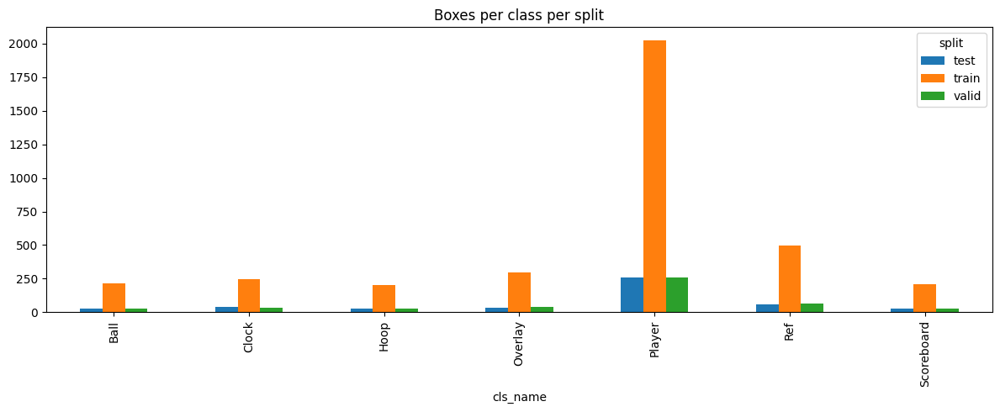

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

ct = df.dropna(subset=["cls"]).groupby(["cls_name", "split"]).size().unstack(fill_value=0)
ct.plot(kind="bar", figsize=(12, 5), title="Boxes per class per split")
plt.tight_layout(); plt.show()

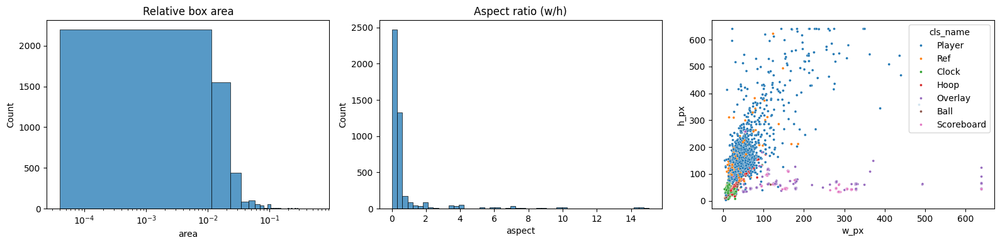

medium    3017
large      919
small      704
Name: count, dtype: int64


In [11]:
d = df.dropna(subset=["cls"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(d["area"], bins=50, ax=ax[0]).set(title="Relative box area", xscale="log")
sns.histplot(d["aspect"], bins=50, ax=ax[1]).set(title="Aspect ratio (w/h)")
sns.scatterplot(data=d.sample(min(5000, len(d))), x="w_px", y="h_px", hue="cls_name", s=8, ax=ax[2])
plt.tight_layout(); plt.show()

# COCO-style size buckets, measured in pixels at original resolution
print(pd.cut(d["w_px"] * d["h_px"], [0, 32**2, 96**2, 1e9], labels=["small", "medium", "large"]).value_counts())

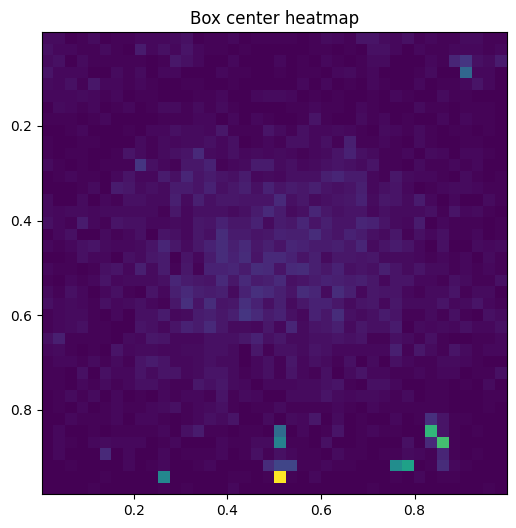

In [12]:
plt.figure(figsize=(6, 6))
plt.hist2d(d["xc"], d["yc"], bins=40, cmap="viridis")
plt.gca().invert_yaxis(); plt.title("Box center heatmap"); plt.show()

In [13]:
# Out-of-range or degenerate boxes
bad = d[(d.xc - d.bw/2 < -0.01) | (d.xc + d.bw/2 > 1.01) |
        (d.yc - d.bh/2 < -0.01) | (d.yc + d.bh/2 > 1.01) |
        (d.bw <= 0) | (d.bh <= 0)]
print("Invalid boxes:", len(bad))

# Tiny boxes (likely label errors)
print("Boxes < 0.1% of image:", (d.area < 0.001).sum())

# Exact duplicate boxes within an image
print("Duplicate boxes:", d.duplicated(["split", "image", "cls", "xc", "yc", "bw", "bh"]).sum())

# Images without labels files vs. empty labels
# Class IDs outside the names range
print("Unknown class IDs:", (~d.cls.isin(names.keys())).sum())

Invalid boxes: 0
Boxes < 0.1% of image: 313
Duplicate boxes: 0
Unknown class IDs: 0


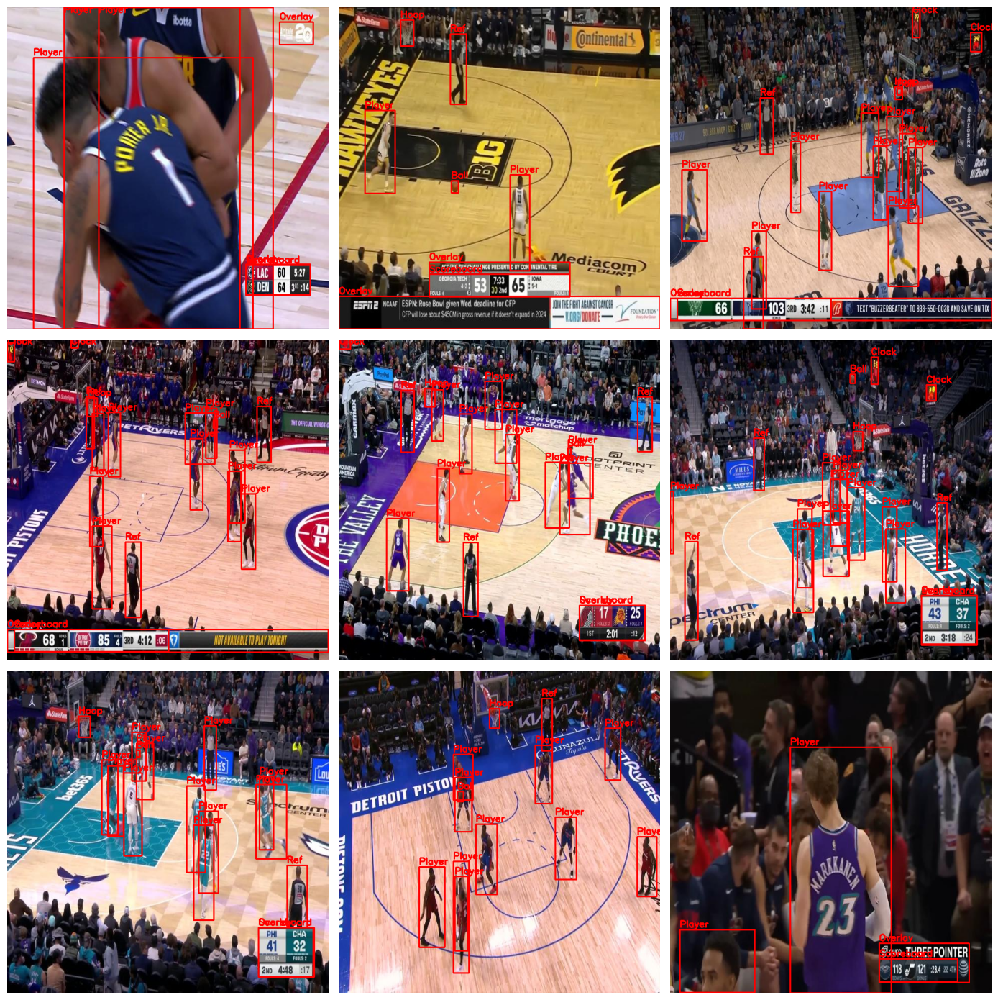

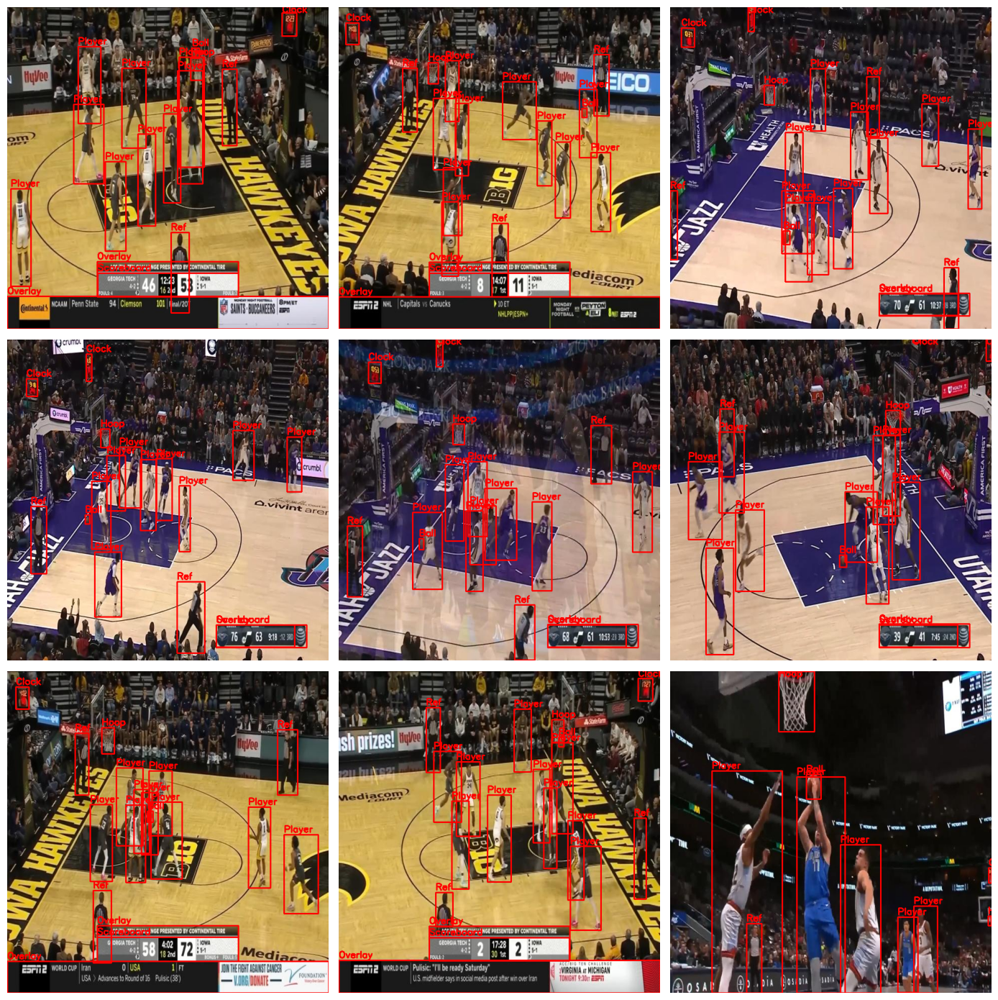

In [15]:
import random
import cv2

def show(split="train", n=9):
    imgs = list((root / split / "images").glob("*"))
    fig, axs = plt.subplots(3, 3, figsize=(14, 14))
    for ax, p in zip(axs.flat, random.sample(imgs, n)):
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        H, W = im.shape[:2]
        lbl = root / split / "labels" / f"{p.stem}.txt"
        if lbl.exists():
            for line in lbl.read_text().splitlines():
                c, xc, yc, bw, bh = line.split()[:5]
                xc, yc, bw, bh = float(xc)*W, float(yc)*H, float(bw)*W, float(bh)*H
                x1, y1, x2, y2 = int(xc-bw/2), int(yc-bh/2), int(xc+bw/2), int(yc+bh/2)
                cv2.rectangle(im, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(im, names[int(c)], (x1, max(y1-5, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
        ax.imshow(im); ax.axis("off")
    plt.tight_layout(); plt.show()

show("train"); show("valid")

## Convert Dataset for Players Only

In [16]:

src = "/kaggle/working/Basketball-Players-17"
dst = "/kaggle/working/Basketball-Players-PlayerOnly"

for split in ["train", "valid", "test"]:
    os.makedirs(f"{dst}/{split}/images", exist_ok=True)
    os.makedirs(f"{dst}/{split}/labels", exist_ok=True)

    image_dir = f"{src}/{split}/images"
    label_dir = f"{src}/{split}/labels"

    for label_file in os.listdir(label_dir):

        if not label_file.endswith(".txt"):
            continue

        src_label = os.path.join(label_dir, label_file)

        player_lines = []

        with open(src_label, "r") as f:
            for line in f:
                parts = line.strip().split()

                if not parts:
                    continue

                class_id = int(parts[0])

                # Player = class 4
                if class_id == 4:
                    parts[0] = "0"
                    player_lines.append(" ".join(parts))

        # Only keep images containing players
        if player_lines:
            # Copy image
            image_name = os.path.splitext(label_file)[0]

            for ext in [".jpg", ".jpeg", ".png"]:
                image_path = os.path.join(image_dir, image_name + ext)

                if os.path.exists(image_path):
                    shutil.copy(
                        image_path,
                        f"{dst}/{split}/images/{image_name}{ext}"
                    )
                    break

            # Write new label
            with open(
                f"{dst}/{split}/labels/{label_file}", "w"
            ) as f:
                f.write("\n".join(player_lines))

In [17]:
yaml_content = """
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['Player']
"""

with open(f"{dst}/data.yaml", "w") as f:
    f.write(yaml_content)

## EDA

### Convert Dataset to DataFrame

In [18]:
from pathlib import Path
import pandas as pd
import yaml
from PIL import Image

root = Path("/kaggle/working/Basketball-Players-PlayerOnly")
names = yaml.safe_load(open(root / "data.yaml"))["names"]
if isinstance(names, list):
    names = dict(enumerate(names))

rows = []
for split in ["train", "valid", "test"]:
    img_dir = root / split / "images"
    lbl_dir = root / split / "labels"
    if not img_dir.exists():
        continue
    for img_path in img_dir.iterdir():
        if img_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
            continue
        w, h = Image.open(img_path).size
        lbl = lbl_dir / f"{img_path.stem}.txt"
        lines = lbl.read_text().strip().splitlines() if lbl.exists() else []
        if not lines:
            rows.append(dict(split=split, image=img_path.name, img_w=w, img_h=h, cls=None))
            continue
        for line in lines:
            parts = line.split()
            c, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:5])
            rows.append(dict(split=split, image=img_path.name, img_w=w, img_h=h,
                             cls=c, xc=xc, yc=yc, bw=bw, bh=bh))

df = pd.DataFrame(rows)
df["cls_name"] = df["cls"].map(names)
df["area"] = df["bw"] * df["bh"]
df["w_px"] = df["bw"] * df["img_w"]
df["h_px"] = df["bh"] * df["img_h"]
df["aspect"] = df["w_px"] / df["h_px"]

In [19]:
print(df.groupby("split")["image"].nunique())          # images per split

split
test      32
train    253
valid     32
Name: image, dtype: int64


In [20]:
print(df.groupby("split").size())                      # boxes per split

split
test      260
train    2021
valid     259
dtype: int64


In [21]:
print(df.groupby("image").size().describe())           # boxes per image (excludes background)

count    317.000000
mean       8.012618
std        2.505658
min        1.000000
25%        7.000000
50%        9.000000
75%       10.000000
max       12.000000
dtype: float64


In [22]:
bg = df[df.cls.isna()].groupby("split")["image"].nunique()
print("Background images:\n", bg)

Background images:
 Series([], Name: image, dtype: int64)


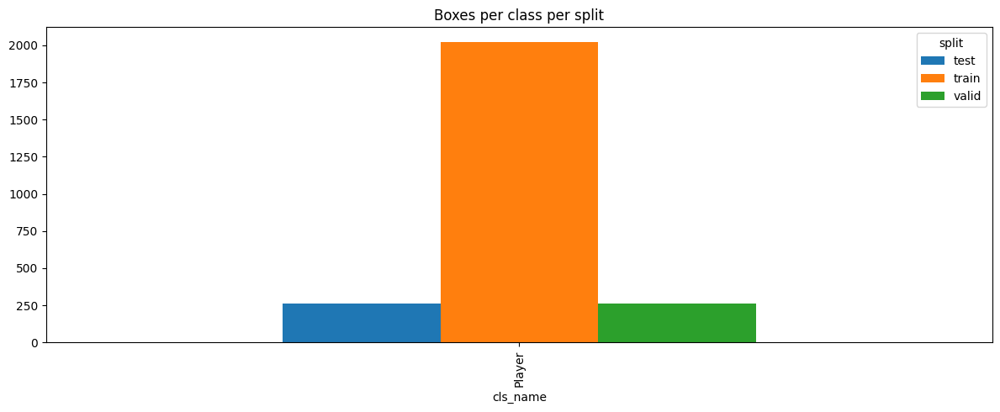

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

ct = df.dropna(subset=["cls"]).groupby(["cls_name", "split"]).size().unstack(fill_value=0)
ct.plot(kind="bar", figsize=(12, 5), title="Boxes per class per split")
plt.tight_layout(); plt.show()

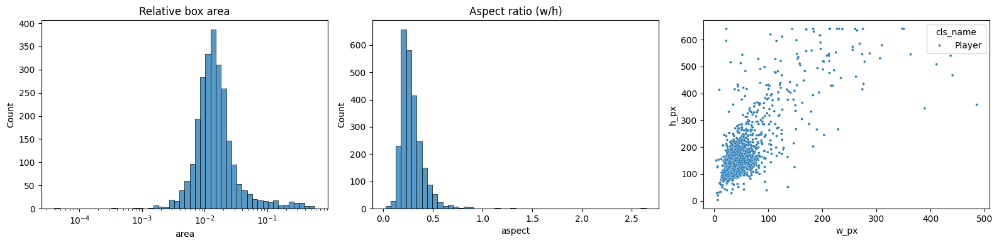

medium    2010
large      511
small       19
Name: count, dtype: int64


In [25]:
d = df.dropna(subset=["cls"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(d["area"], bins=50, ax=ax[0], log_scale=True).set(title="Relative box area", xscale="log")
sns.histplot(d["aspect"], bins=50, ax=ax[1]).set(title="Aspect ratio (w/h)")
sns.scatterplot(data=d.sample(min(5000, len(d))), x="w_px", y="h_px", hue="cls_name", s=8, ax=ax[2])
plt.tight_layout(); plt.show()

# COCO-style size buckets, measured in pixels at original resolution
print(pd.cut(d["w_px"] * d["h_px"], [0, 32**2, 96**2, 1e9], labels=["small", "medium", "large"]).value_counts())

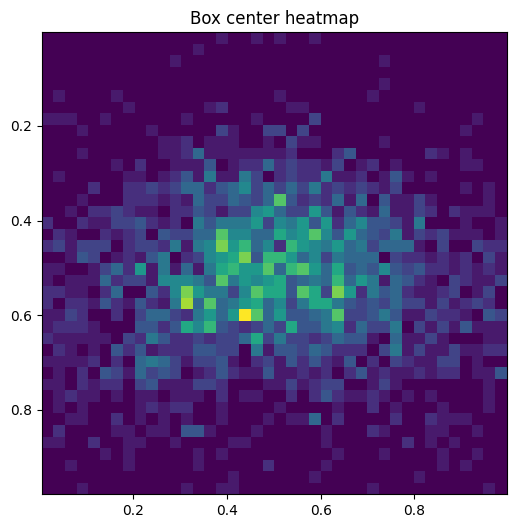

In [26]:
plt.figure(figsize=(6, 6))
plt.hist2d(d["xc"], d["yc"], bins=40, cmap="viridis")
plt.gca().invert_yaxis(); plt.title("Box center heatmap"); plt.show()

In [28]:
# Out-of-range or degenerate boxes
bad = d[(d.xc - d.bw/2 < -0.01) | (d.xc + d.bw/2 > 1.01) |
        (d.yc - d.bh/2 < -0.01) | (d.yc + d.bh/2 > 1.01) |
        (d.bw <= 0) | (d.bh <= 0)]
print("Invalid boxes:", len(bad))

# Tiny boxes (likely label errors)
print("Boxes < 0.1% of image:", (d.area < 0.001).sum())

# Exact duplicate boxes within an image
print("Duplicate boxes:", d.duplicated(["split", "image", "cls", "xc", "yc", "bw", "bh"]).sum())

# Images without labels files vs. empty labels
# Class IDs outside the names range
print("Unknown class IDs:", (~d.cls.isin(names.keys())).sum())

Invalid boxes: 0
Boxes < 0.1% of image: 5
Duplicate boxes: 0
Unknown class IDs: 0


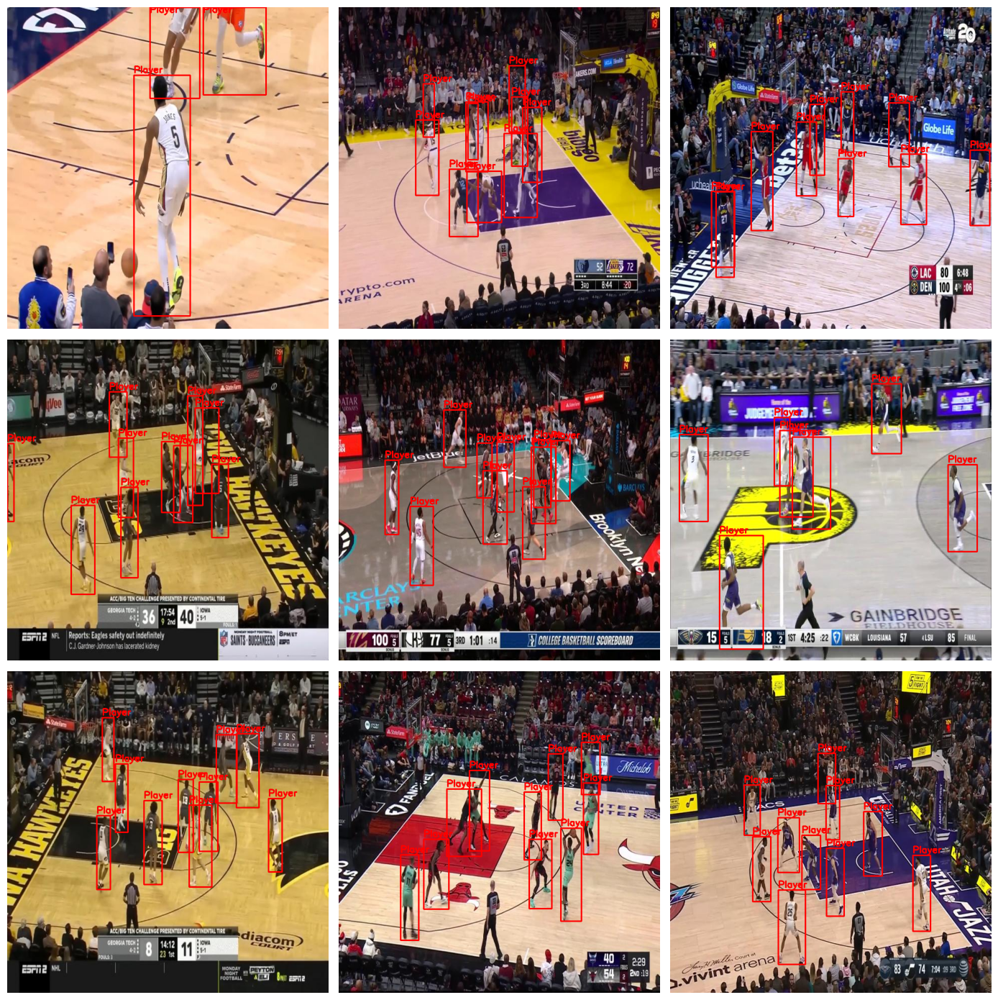

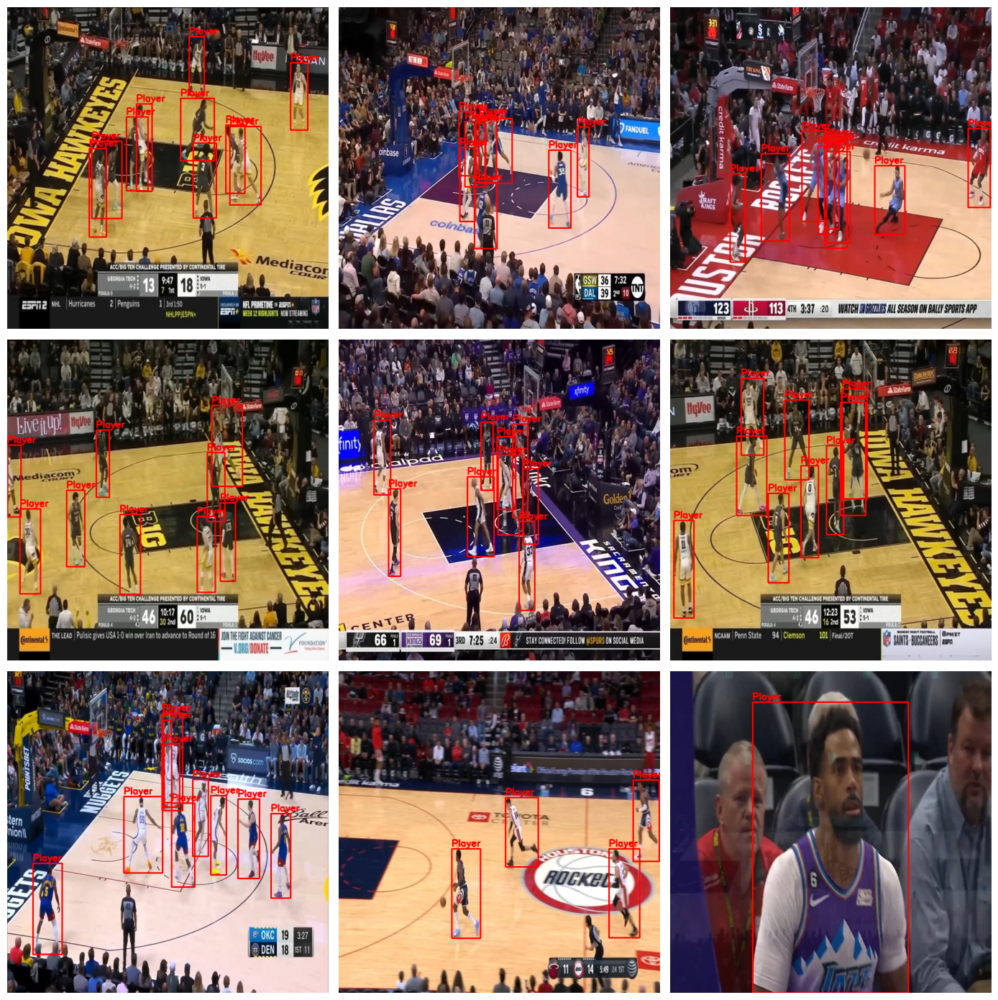

In [29]:
import random
import cv2

def show(split="train", n=9):
    imgs = list((root / split / "images").glob("*"))
    fig, axs = plt.subplots(3, 3, figsize=(14, 14))
    for ax, p in zip(axs.flat, random.sample(imgs, n)):
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        H, W = im.shape[:2]
        lbl = root / split / "labels" / f"{p.stem}.txt"
        if lbl.exists():
            for line in lbl.read_text().splitlines():
                c, xc, yc, bw, bh = line.split()[:5]
                xc, yc, bw, bh = float(xc)*W, float(yc)*H, float(bw)*W, float(bh)*H
                x1, y1, x2, y2 = int(xc-bw/2), int(yc-bh/2), int(xc+bw/2), int(yc+bh/2)
                cv2.rectangle(im, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(im, names[int(c)], (x1, max(y1-5, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
        ax.imshow(im); ax.axis("off")
    plt.tight_layout(); plt.show()

show("train"); show("valid")

In [ ]:
from ultralytics import YOLO

for size in ["11s", "11m", "11x"]:
    model = YOLO(f"yolo{size}.pt")
    model.train(
        data="/kaggle/working/Basketball-Players-PlayerOnly/data.yaml",
        epochs=150,
        imgsz=640,
        batch=16,
        patience=30,
        seed=0,
        project="runs",
        name=f"yolo{size}_base",
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Basketball-Players-PlayerOnly/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


      2/150      5.02G       1.58      1.673      1.418        124        640: 100% ━━━━━━━━━━━━ 16/16 5.9it/s 2.7s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.4it/s 0.4s
                   all         32        259      0.561      0.544      0.509      0.282

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/150      5.04G      1.754      1.482      1.496        158        640: 100% ━━━━━━━━━━━━ 16/16 5.8it/s 2.7s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.6it/s 0.4s
                   all         32        259   0.000328     0.0116   5.46e-06   1.09e-06

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/150      5.04G      1.755      1.539      1.545        154        640: 100% ━━━━━━━━━━━━ 16/16 5.9it/s 2.7s0.2s
                 Class     Images  Instances      Box(